In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, Model
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

IMG_PATH  = '/content/drive/MyDrive/EdgeTB_Project/datasets/montgomery/Montgomery/Montgomery/img'
MASK_PATH = '/content/drive/MyDrive/EdgeTB_Project/datasets/montgomery/Montgomery/Montgomery/mask'
IMG_SIZE  = 256  # resize everything to 256x256

def load_data(img_path, mask_path, img_size):
    images = []
    masks  = []

    filenames = sorted([f for f in os.listdir(img_path) if f.endswith('.png')])

    for fname in filenames:
        # load image and convert to greyscale
        img = Image.open(os.path.join(img_path, fname)).convert('L')
        img = img.resize((img_size, img_size))
        img = np.array(img) / 255.0  # normalise to 0-1
        img = np.expand_dims(img, axis=-1)  # add channel dimension
        images.append(img)

        # load mask and convert to binary (0 or 1)
        mask = Image.open(os.path.join(mask_path, fname)).convert('L')
        mask = mask.resize((img_size, img_size))
        mask = np.array(mask) / 255.0
        mask = (mask > 0.5).astype(np.float32)  # threshold to binary
        mask = np.expand_dims(mask, axis=-1)
        masks.append(mask)

    return np.array(images), np.array(masks)

print("Loading images and masks...")
X, y = load_data(IMG_PATH, MASK_PATH, IMG_SIZE)
print(f"Images shape: {X.shape}")
print(f"Masks shape:  {y.shape}")

Loading images and masks...
Images shape: (138, 256, 256, 1)
Masks shape:  (138, 256, 256, 1)


In [ ]:
# split into 80% train, 20% val
# 138 images is small so we keep more for training
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape[0]} images")
print(f"Val:   {X_val.shape[0]} images")

Train: 110 images
Val:   28 images


In [ ]:
def unet(input_size=(256, 256, 1)):
    inputs = layers.Input(input_size)

    # encoder — shrinks the image and extracts features
    # each block: two convolutions then a max pool to halve the size
    c1 = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(32, 3, activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D()(c1)

    c2 = layers.Conv2D(64, 3, activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(64, 3, activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D()(c2)

    c3 = layers.Conv2D(128, 3, activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(128, 3, activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D()(c3)

    # bottleneck — deepest part of the U
    c4 = layers.Conv2D(256, 3, activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(256, 3, activation='relu', padding='same')(c4)

    # decoder — expands back to original size
    # skip connections (concatenate) bring back detail from the encoder
    u5 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c4)
    u5 = layers.concatenate([u5, c3])
    c5 = layers.Conv2D(128, 3, activation='relu', padding='same')(u5)
    c5 = layers.Conv2D(128, 3, activation='relu', padding='same')(c5)

    u6 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c5)
    u6 = layers.concatenate([u6, c2])
    c6 = layers.Conv2D(64, 3, activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(64, 3, activation='relu', padding='same')(c6)

    u7 = layers.Conv2DTranspose(32, 2, strides=2, padding='same')(c6)
    u7 = layers.concatenate([u7, c1])
    c7 = layers.Conv2D(32, 3, activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(32, 3, activation='relu', padding='same')(c7)

    # output layer — one filter with sigmoid gives a mask between 0 and 1
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c7)

    return Model(inputs, outputs)

model = unet()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 64, 64,    │    131,200 │ conv2d_7[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 256)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 64, 64,    │    295,040 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_8[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 128, 128,  │     32,832 │ conv2d_9[0][0]  

 Total params: 1,925,025 (7.34 MB)

 Trainable params: 1,925,025 (7.34 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# dice loss works better than binary crossentropy for segmentation
# because it directly optimises the overlap between predicted and actual mask
def dice_loss(y_true, y_pred):
    smooth = 1e-6
    intersection = tf.reduce_sum(y_true * y_pred)
    return 1 - (2 * intersection + smooth) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

model.compile(
    optimizer='adam',
    loss=dice_loss,
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        '/content/drive/MyDrive/EdgeTB_Project/models/unet_lung.h5',
        monitor='val_loss', save_best_only=True
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=8,  # small batch because images are large
    callbacks=callbacks
)

print("Training done")

Epoch 1/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6289 - loss: 0.6522   

14/14 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.6003 - loss: 0.6461 - val_accuracy: 0.6343 - val_loss: 0.5478
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.6827 - loss: 0.4200

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step - accuracy: 0.7859 - loss: 0.3102 - val_accuracy: 0.9287 - val_loss: 0.1319
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.9307 - loss: 0.1399

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 144ms/step - accuracy: 0.9294 - loss: 0.1424 - val_accuracy: 0.9434 - val_loss: 0.1091
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.9407 - loss: 0.1113

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 0.9463 - loss: 0.1057 - val_accuracy: 0.9546 - val_loss: 0.0861
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.9603 - loss: 0.0772

...

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 151ms/step - accuracy: 0.9896 - loss: 0.0205 - val_accuracy: 0.9839 - val_loss: 0.0309
Epoch 38/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.9907 - loss: 0.0184 - val_accuracy: 0.9838 - val_loss: 0.0311
Epoch 39/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 136ms/step - accuracy: 0.9908 - loss: 0.0183 - val_accuracy: 0.9836 - val_loss: 0.0316
Epoch 40/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.9906 - loss: 0.0187

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 169ms/step - accuracy: 0.9907 - loss: 0.0186 - val_accuracy: 0.9844 - val_loss: 0.0301
Epoch 41/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.9911 - loss: 0.0174

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 150ms/step - accuracy: 0.9913 - loss: 0.0173 - val_accuracy: 0.9845 - val_loss: 0.0300
Epoch 42/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.9911 - loss: 0.0175 - val_accuracy: 0.9840 - val_loss: 0.0306
Epoch 43/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.9904 - loss: 0.0189 - val_accuracy: 0.9842 - val_loss: 0.0306
Epoch 44/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - accuracy: 0.9907 - loss: 0.0183 - val_accuracy: 0.9833 - val_loss: 0.0326
Epoch 45/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.9911 - loss: 0.0179

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 152ms/step - accuracy: 0.9912 - loss: 0.0175 - val_accuracy: 0.9847 - val_loss: 0.0296
Epoch 46/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step - accuracy: 0.9908 - loss: 0.0182 - val_accuracy: 0.9824 - val_loss: 0.0336
Epoch 47/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step - accuracy: 0.9902 - loss: 0.0196 - val_accuracy: 0.9820 - val_loss: 0.0346
Epoch 48/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.9910 - loss: 0.0179 - val_accuracy: 0.9844 - val_loss: 0.0303
Epoch 49/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.9918 - loss: 0.0162

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 150ms/step - accuracy: 0.9918 - loss: 0.0164 - val_accuracy: 0.9848 - val_loss: 0.0292
Epoch 50/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.9923 - loss: 0.0154 - val_accuracy: 0.9847 - val_loss: 0.0294
Training done


1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step


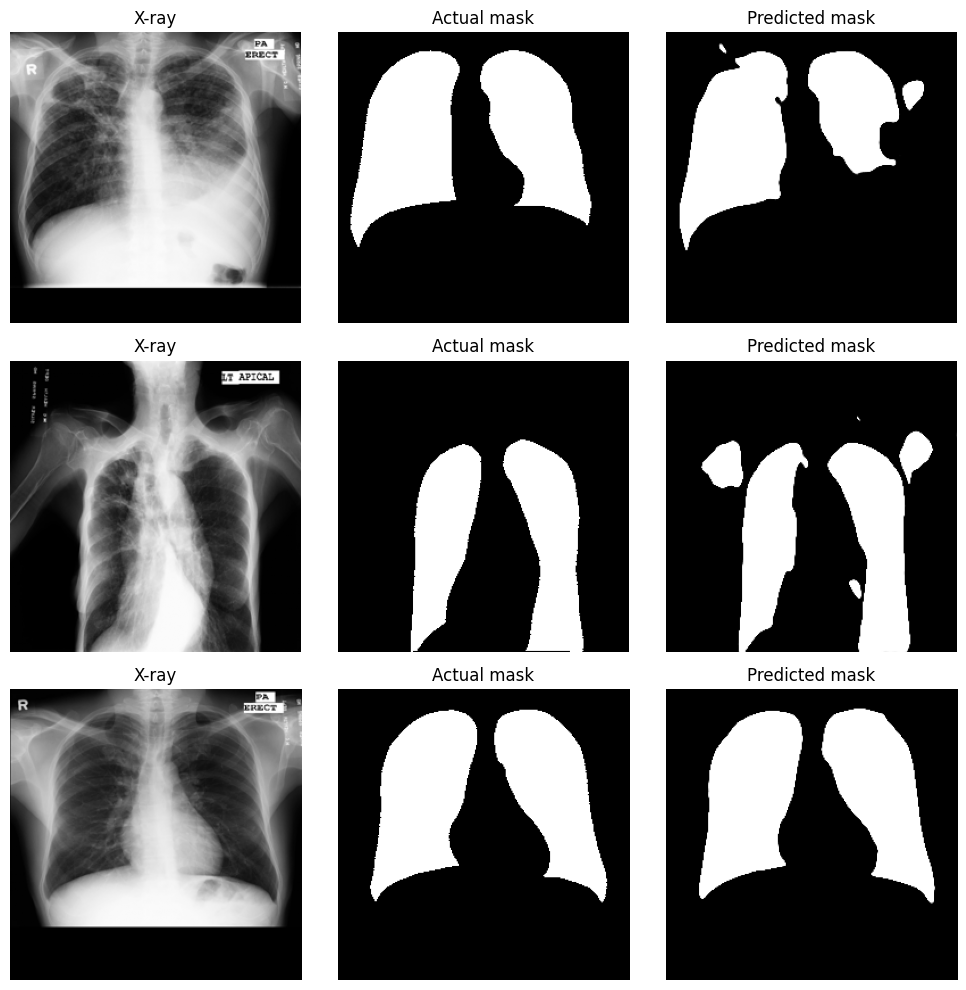

Sample predictions saved


In [ ]:
# looking at a few predictions to see if segmentation is working
preds = model.predict(X_val)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i in range(3):
    axes[i, 0].imshow(X_val[i, :, :, 0], cmap='gray')
    axes[i, 0].set_title('X-ray')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(y_val[i, :, :, 0], cmap='gray')
    axes[i, 1].set_title('Actual mask')
    axes[i, 1].axis('off')

    axes[i, 2].imshow(preds[i, :, :, 0], cmap='gray')
    axes[i, 2].set_title('Predicted mask')
    axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EdgeTB_Project/results/evaluation/unet_predictions.png')
plt.show()
print("Sample predictions saved")

In [ ]:
# dice score measures overlap between predicted and actual mask

def dice_score(y_true, y_pred, threshold=0.5):
    y_pred = (y_pred > threshold).astype(np.float32)
    intersection = np.sum(y_true * y_pred)
    return (2 * intersection) / (np.sum(y_true) + np.sum(y_pred) + 1e-6)

# run on all validation images
scores = []
preds  = model.predict(X_val)

for i in range(len(X_val)):
    score = dice_score(y_val[i], preds[i])
    scores.append(score)

mean_dice = np.mean(scores)
print(f"Mean Dice Score on validation set: {mean_dice:.4f}")
print(f"Min: {min(scores):.4f}  |  Max: {max(scores):.4f}")

# save the score
with open('/content/drive/MyDrive/EdgeTB_Project/results/evaluation/unet_dice_score.txt', 'w') as f:
    f.write(f"U-Net Lung Segmentation - Dice Score\n")
    f.write(f"Validation set: {len(X_val)} images\n")
    f.write(f"Mean Dice Score: {mean_dice:.4f}\n")
    f.write(f"Min: {min(scores):.4f}\n")
    f.write(f"Max: {max(scores):.4f}\n")

print("Score saved to Drive")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step
Mean Dice Score on validation set: 0.9685
Min: 0.8782  |  Max: 0.9877
Score saved to Drive


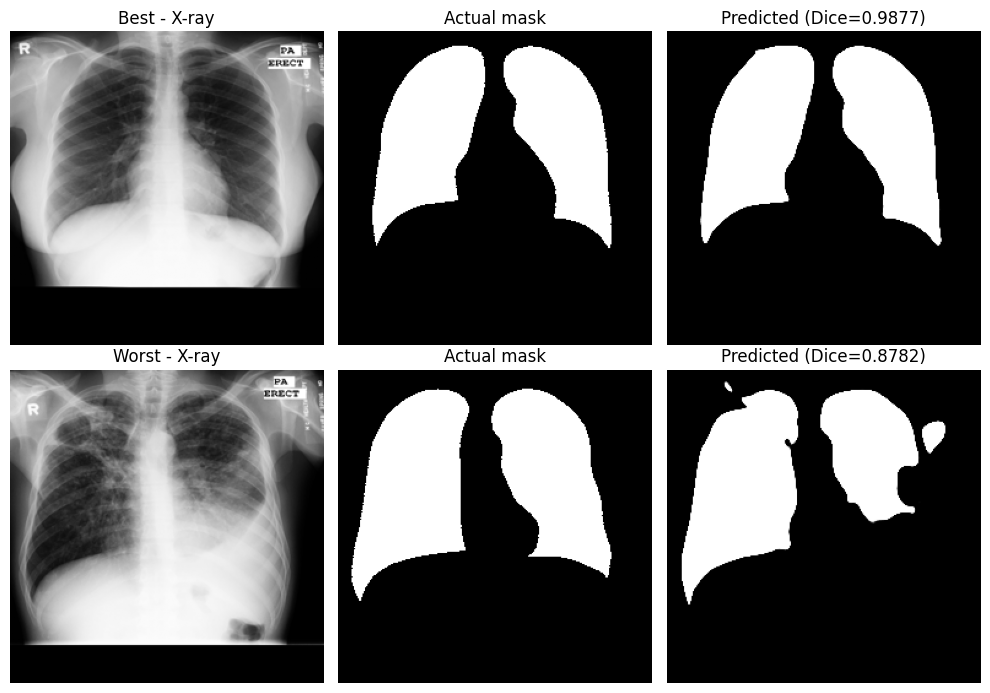

Best and worst predictions saved


In [ ]:
# saving a sample of the worst and best predictions
worst_idx = np.argmin(scores)
best_idx  = np.argmax(scores)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for row, idx, label in [(0, best_idx, 'Best'), (1, worst_idx, 'Worst')]:
    axes[row, 0].imshow(X_val[idx, :, :, 0], cmap='gray')
    axes[row, 0].set_title(f'{label} - X-ray')
    axes[row, 0].axis('off')

    axes[row, 1].imshow(y_val[idx, :, :, 0], cmap='gray')
    axes[row, 1].set_title('Actual mask')
    axes[row, 1].axis('off')

    axes[row, 2].imshow(preds[idx, :, :, 0], cmap='gray')
    axes[row, 2].set_title(f'Predicted (Dice={scores[idx]:.4f})')
    axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EdgeTB_Project/results/evaluation/unet_best_worst.png')
plt.show()
print("Best and worst predictions saved")